# INFOCOM RAN updates dataset preparation

The code and data are from https://github.com/nds-group/ran-updates.

In [85]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt
import os
import numpy as np

In [86]:
# select the granularity of data and event type
granularity = 'hour' # hour or day
event_type = "4G addition" # both or 4G addition or 5G addition

In [87]:
# load data
df_traffic = pd.read_parquet('/nas_datasets/traffic_datasets/public_datasets/ran_updates/traffic_dataset.parquet')
df_info_full = pd.read_parquet('/nas_datasets/traffic_datasets/public_datasets/ran_updates/info_dataset.parquet')

## Data investigation

In [88]:
df_info_full['event_type'].unique(), df_info_full['urbanization'].unique(), len(df_info_full['UUID'].unique()), len(df_traffic['UUID'].unique())

(array(['5G addition', '4G addition'], dtype=object),
 array(['Suburban', 'Urban', 'Metropolitan', 'Rural',
        'Metropolitan Center'], dtype=object),
 1931,
 1931)

In [89]:
df_info_full['urbanization'].value_counts()

urbanization
Suburban               1151
Rural                   486
Urban                   149
Metropolitan            132
Metropolitan Center      13
Name: count, dtype: int64

In [90]:
df_info_full['technology'].unique()

array(['4G'], dtype=object)

In [91]:
if event_type == 'both':
    df_info = df_info_full.copy()
elif event_type == "4G addition" or event_type == "5G addition":
    df_info = df_info_full[df_info_full["event_type"] == event_type].copy()
else: 
    raise Exception('Incorrect event type')

In [92]:
# Get a single carrier's time series
random_antenna = 100
sample_uuid = df_info['UUID'].iloc[random_antenna]
sample_antennaID = df_info['antennaID'].iloc[random_antenna]
sample_urbanization = df_info['urbanization'].iloc[random_antenna]
sample_technology = df_info['technology'].iloc[random_antenna]
sample_event_type = df_info['event_type'].iloc[random_antenna]

carrier_traffic = df_traffic[df_traffic['UUID'] == sample_uuid].copy()
carrier_traffic = carrier_traffic.sort_values('deltaT').reset_index(drop=True)

# Convert deltaT to days and aggregate to daily level
carrier_traffic['days'] = carrier_traffic['deltaT'] / 3600 / 24
daily_traffic = carrier_traffic.groupby(carrier_traffic['days'].astype(int))['DL'].sum()

carrier_traffic['hours'] = carrier_traffic['deltaT'] / 3600
hourly_traffic = carrier_traffic.groupby(carrier_traffic['hours'].astype(int))['DL'].sum()

In [93]:
carrier_traffic

,UUID,DL,UL,deltaT,days,hours
0,b044612923bffaeb,2.541297,2.058171,-5356800.0,-62.000000,-1488.0
1,b044612923bffaeb,-0.340770,-0.242527,-5353200.0,-61.958333,-1487.0
2,b044612923bffaeb,-0.685228,-0.625099,-5349600.0,-61.916667,-1486.0
3,b044612923bffaeb,-0.265723,-0.523676,-5346000.0,-61.875000,-1485.0
4,b044612923bffaeb,-0.368930,-0.384870,-5342400.0,-61.833333,-1484.0
...,...,...,...,...,...,...
3018,b044612923bffaeb,0.852671,0.528933,5508000.0,63.750000,1530.0
3019,b044612923bffaeb,0.403827,-0.313447,5511600.0,63.791667,1531.0
3020,b044612923bffaeb,-0.530254,1.801883,5515200.0,63.833333,1532.0
3021,b044612923bffaeb,0.136083,0.178571,5518800.0,63.875000,1533.0


In [94]:
if granularity == 'hour':
    traffic = hourly_traffic
    event_length = 7*24  # 168 hours (1 week)
    decomposition = seasonal_decompose(traffic, model='additive', period=24) # 24 hours as period
elif granularity == 'day':
    traffic = daily_traffic
    event_length = 7  # 1 week
    decomposition = seasonal_decompose(traffic, model='additive', period=7) # weekly
else: 
    raise Exception('Incorrect granularity --> update the code to use the granularity you want starting from hours')

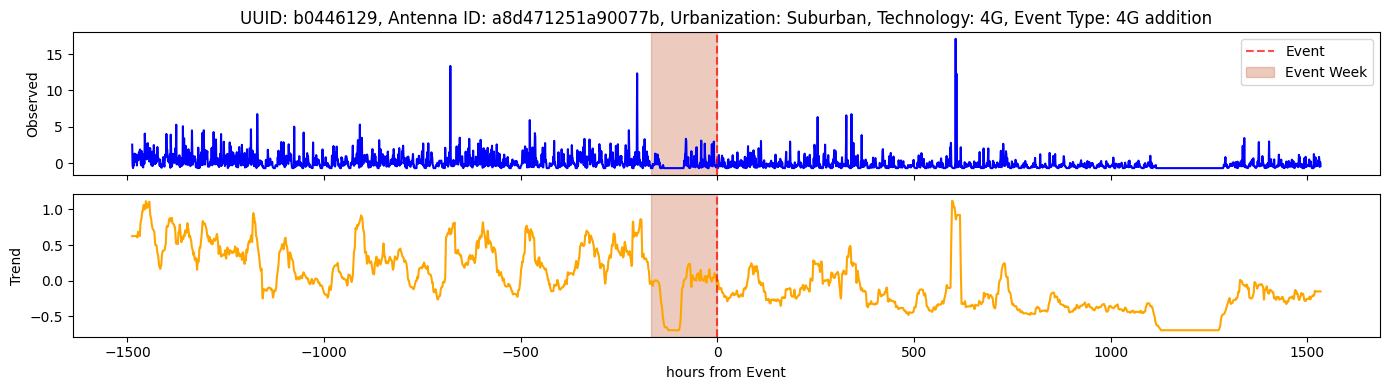

In [95]:
# Plot the decomposition
fig, axes = plt.subplots(2, 1, figsize=(14, 4), sharex=True)

axes[0].plot(traffic.index, decomposition.observed, color='blue')
axes[0].axvline(x=0, color='red', linestyle='--', alpha=0.7, label='Event')
axes[0].axvspan(-event_length,  0, alpha=0.4, color='#d17c5a', label='Event Week')
axes[0].set_ylabel('Observed')
axes[0].set_title(f'UUID: {sample_uuid[:8]}, Antenna ID: {sample_antennaID}, Urbanization: {sample_urbanization}, Technology: {sample_technology}, Event Type: {sample_event_type}')
axes[0].legend()

axes[1].plot(traffic.index, decomposition.trend.ffill().bfill(), color='orange')
axes[1].axvline(x=0, color='red', linestyle='--', alpha=0.7)
axes[1].axvspan(-event_length,  0, alpha=0.4, color='#d17c5a', label='Event Week')

axes[1].set_ylabel('Trend')
axes[1].set_xlabel(f'{granularity}s from Event')

plt.tight_layout()
# plt.savefig('time_series_decomposition.png', dpi=300)
plt.show()

In [96]:
len(decomposition.trend), len(decomposition.observed)

(3023, 3023)

In [97]:
type(decomposition.observed)

pandas.core.series.Series

In [98]:
np.where(np.isclose(traffic.index.values, 0.0))[0]

array([1488])

## Loop over antennas to create dataset

# 50 first

In [99]:
# filename = f'ran_updates_event_{event_type}_{granularity}_granularity.csv'
# if os.path.exists(filename):
#     os.remove(filename)

# filename_trend = f'ran_updates_event_{event_type}_{granularity}_granularity_trend.csv'
# if os.path.exists(filename_trend):
#     os.remove(filename_trend)

# drift_labels_file = f"drift_labels_ran_updates_event_{event_type}_{granularity}_granularity.csv"
# if os.path.exists(drift_labels_file):
#     os.remove(drift_labels_file)

# # for antenna in range(0, len(df_info['UUID'].unique())):
# for antenna in range(0, 50):
#     sample_uuid = df_info['UUID'].iloc[antenna]

#     carrier_traffic = df_traffic[df_traffic['UUID'] == sample_uuid].copy()
#     carrier_traffic = carrier_traffic.sort_values('deltaT').reset_index(drop=True)

#     if granularity == 'hour':
#         carrier_traffic['hours'] = carrier_traffic['deltaT'] / 3600
#         traffic = carrier_traffic.groupby(carrier_traffic['hours'].astype(int))['DL'].mean()
#         event_length = 7*24  # 168 hours (1 week)
#         decomposition = seasonal_decompose(traffic, model='additive', period=24) # 24 hours as period
#     elif granularity == 'day':
#         # Convert deltaT to days and aggregate to daily level
#         carrier_traffic['days'] = carrier_traffic['deltaT'] / 3600 / 24
#         traffic = carrier_traffic.groupby(carrier_traffic['days'].astype(int))['DL'].mean()
#         event_length = 7  # 1 week
#         decomposition = seasonal_decompose(traffic, model='additive', period=7) # weekly


#     # save file with the first raw being traffic index (0 is the event day) and the rest are traffic time series from antennas
#     df = pd.DataFrame({k:[v] for k, v in zip(traffic.index.values, decomposition.observed.values)})
#     # write_header = not os.path.exists(filename)
#     df.to_csv(filename, mode="a", header=False, index=False)

#     with open(f"drift_labels_ran_updates_event_{event_type}_{granularity}_granularity.csv", "a") as file:
#         np.savetxt(file, [np.where(np.isclose(traffic.index.values, 0.0))[0]], delimiter=",", fmt="%.6f")

#     # save also trend of data
#     df = pd.DataFrame({k:[v] for k, v in zip(traffic.index.values, decomposition.trend.ffill().bfill().values)})
#     # write_header = not os.path.exists(filename_trend)
#     df.to_csv(filename_trend, mode="a", header=False, index=False)


# Priotirize no missing data and higher difference according to wilcoxon text

In [100]:
from scipy.stats import wilcoxon  
columns = ['UUID', 'missing_data_per', 'p_value']
df_sorting = pd.DataFrame(columns=columns)

for antenna in range(0, len(df_info['UUID'].unique())):
    sample_uuid = df_info['UUID'].iloc[antenna]

    carrier_traffic = df_traffic[df_traffic['UUID'] == sample_uuid].copy()
    carrier_traffic = carrier_traffic.sort_values('deltaT').reset_index(drop=True)

    if granularity == 'hour':
        carrier_traffic['hours'] = carrier_traffic['deltaT'] / 3600
        traffic = carrier_traffic.groupby(carrier_traffic['hours'].astype(int))['DL'].mean()
        event_length = 7*24  # 168 hours (1 week)
        decomposition = seasonal_decompose(traffic, model='additive', period=24) # 24 hours as period
    elif granularity == 'day':
        # Convert deltaT to days and aggregate to daily level
        carrier_traffic['days'] = carrier_traffic['deltaT'] / 3600 / 24
        traffic = carrier_traffic.groupby(carrier_traffic['days'].astype(int))['DL'].mean()
        event_length = 7  # 1 week
        decomposition = seasonal_decompose(traffic, model='additive', period=7) # weekly

    min_len = min(len(traffic[traffic.index < 0]), len(traffic[traffic.index >= 0]))
    before = traffic[(traffic.index < 0) & (traffic.index > -min_len-1)]
    after = traffic[(traffic.index >= 0) & (traffic.index < min_len)]
    stat, p_value = wilcoxon(before, after)
    # missing_data = traffic.isna().mean() * 100

    min_val = traffic.min()
    # Boolean mask where value equals minimum
    mask = traffic.eq(min_val)
    # Group consecutive True/False values
    groups = mask.ne(mask.shift()).cumsum()
    # Length of each consecutive block
    run_lengths = mask.groupby(groups).transform('size')
    # Keep only True runs with length >= 20
    stable = mask & (run_lengths >= 20)
    regions = (
        traffic[stable]
        .groupby(groups[stable])
        .apply(lambda x: (x.index[0], x.index[-1], len(x)))
    )

    percentage = 100 * stable.sum() / len(traffic)
    new_row = pd.DataFrame([{columns[0]: sample_uuid, columns[1]: percentage, columns[2]: p_value}])
    df_sorting = pd.concat([df_sorting, new_row], ignore_index=True)            
    

In [101]:
df_sorting

,UUID,missing_data_per,p_value
0,087e8c0bcfa0b2f0,0.000000,3.645811e-24
1,b3dc4a7d2f4e3467,1.017187,9.498556e-14
2,9295c4e0ae88cbe5,1.050788,1.922094e-58
3,1e381d69f8d2d727,1.050788,1.222790e-116
4,7b1c37896e0f53a6,2.626970,1.313025e-50
...,...,...,...
1044,592f56eafee610f1,3.305785,4.270921e-20
1045,306aefe48df7da27,3.272727,2.733677e-46
1046,05ced76b54e93b1c,2.644628,1.864206e-27
1047,7e333d51bdba0075,1.652893,7.721950e-22


In [102]:
df_sorted = df_sorting.sort_values(
    by=["missing_data_per", "p_value"],
    ascending=[True, True]  
)
df_sorted

,UUID,missing_data_per,p_value
95,adcbfa7b8a372f6b,0.000000,5.773363e-235
716,f80b5aeb8e1657b2,0.000000,1.030309e-205
861,3c7c3a9b1bff0ba9,0.000000,3.878495e-200
726,543ec130943d8115,0.000000,3.174457e-197
797,0b6482be4ea3356d,0.000000,1.185301e-192
...,...,...,...
754,4cb38b627491babc,11.702479,2.257679e-58
522,fc1b6c73b70edb73,14.290440,2.232118e-92
376,3b944fc09df2f64a,15.376984,3.749205e-43
322,414f6501172526cd,19.237260,8.599602e-27


In [103]:
selected_uuids = df_sorted["UUID"].head(50).tolist()
selected_uuids

['adcbfa7b8a372f6b',
 'f80b5aeb8e1657b2',
 '3c7c3a9b1bff0ba9',
 '543ec130943d8115',
 '0b6482be4ea3356d',
 '6248f371f781ff78',
 'ed067a15571f893f',
 '9de1c9641135751d',
 '0133b5bae8a6bb7d',
 'e99239f309916a16',
 '330bb5529c6a4479',
 '89e217a77a2f39cc',
 '05aa6a413e0c987a',
 '8dd3af477445f2e6',
 'a3fb401447792ce1',
 '000fd584544a84d8',
 'e82b32f08738ce1c',
 '75447715611071b5',
 '6b765387d531abfb',
 '8079bb64eb694846',
 '29b449c52a5d40f3',
 '5070a035605dc0df',
 'dee3c0b23470ea3a',
 '510d11fc402c2ed8',
 '1e9e32bf472ae36d',
 '7e370ce3a9eaa4f6',
 '2a1e58259d221383',
 'e4de06b7812a5405',
 '371a592c54a28a97',
 'dfa2f17e7a5f02d9',
 'e35536149f898360',
 '9d41cd15090f95e2',
 '9d358d3611008992',
 '25c4a43cc643c849',
 'c293441f04f03a75',
 '236fe152a78b1685',
 'b114a9a2ce62d1dd',
 '9f71a11123f56c5b',
 '5246a1dbd47bf1e5',
 '6de3a6c00935055b',
 '4d8c82c7dac6c236',
 '642cfa7b3797c16e',
 '4d99e7be6193e5f9',
 '382620eef141c432',
 '064da1cbd17b34dd',
 '9aeeb0afa3dbe9b6',
 '1dbcef81acf292b2',
 '964b0c44e6d

In [104]:
antenna

1048

In [105]:
filename = f'ran_updates_event_{event_type}_{granularity}_granularity.csv'
if os.path.exists(filename):
    os.remove(filename)

filename_trend = f'ran_updates_event_{event_type}_{granularity}_granularity_trend.csv'
if os.path.exists(filename_trend):
    os.remove(filename_trend)

drift_labels_file = f"drift_labels_ran_updates_event_{event_type}_{granularity}_granularity.csv"
if os.path.exists(drift_labels_file):
    os.remove(drift_labels_file)

# for antenna in range(0, len(df_info['UUID'].unique())):
# for antenna in range(0, 50):
for antenna in selected_uuids:
    # sample_uuid = df_info['UUID'].iloc[antenna]
    sample_uuid = antenna

    carrier_traffic = df_traffic[df_traffic['UUID'] == sample_uuid].copy()
    carrier_traffic = carrier_traffic.sort_values('deltaT').reset_index(drop=True)

    if granularity == 'hour':
        carrier_traffic['hours'] = carrier_traffic['deltaT'] / 3600
        traffic = carrier_traffic.groupby(carrier_traffic['hours'].astype(int))['DL'].mean()
        event_length = 7*24  # 168 hours (1 week)
        decomposition = seasonal_decompose(traffic, model='additive', period=24) # 24 hours as period
    elif granularity == 'day':
        # Convert deltaT to days and aggregate to daily level
        carrier_traffic['days'] = carrier_traffic['deltaT'] / 3600 / 24
        traffic = carrier_traffic.groupby(carrier_traffic['days'].astype(int))['DL'].mean()
        event_length = 7  # 1 week
        decomposition = seasonal_decompose(traffic, model='additive', period=7) # weekly


    # save file with the first raw being traffic index (0 is the event day) and the rest are traffic time series from antennas
    df = pd.DataFrame({k:[v] for k, v in zip(traffic.index.values, decomposition.observed.values)})
    # write_header = not os.path.exists(filename)
    df.to_csv(filename, mode="a", header=False, index=False)

    with open(f"drift_labels_ran_updates_event_{event_type}_{granularity}_granularity.csv", "a") as file:
        np.savetxt(file, [np.where(np.isclose(traffic.index.values, 0.0))[0]], delimiter=",", fmt="%.6f")

    # save also trend of data
    df = pd.DataFrame({k:[v] for k, v in zip(traffic.index.values, decomposition.trend.ffill().bfill().values)})
    # write_header = not os.path.exists(filename_trend)
    df.to_csv(filename_trend, mode="a", header=False, index=False)
